<!-- Data understanding and profiling -->

IMPORTING LIBRARIES

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("opensky_data_uncleaned.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (7561, 16)


,icao24,callsign,origin_country,time_position,last_constant,longitude,latitude,baro_altitude,on_ground,velocity,true_track,vertical_rate,geo_altitude,squawk,spi,position_source
0,80162d,AXB848,India,1.767745e+09,1767745048,52.7391,25.4425,9608.82,False,257.34,119.59,5.20,9829.80,3112.0,False,0
1,ae1fa0,72209,United States,1.767745e+09,1767745047,-84.9380,38.1463,571.50,False,73.38,12.96,0.33,487.68,NaN,False,0
2,ac96b8,AAL1175,United States,1.767745e+09,1767745048,-102.0238,34.0962,10363.20,False,196.90,291.13,0.00,10683.24,NaN,False,0
3,c81bd3,ZKAMK,New Zealand,1.767745e+09,1767744917,174.5408,-35.8060,624.84,False,56.90,165.34,0.65,670.56,NaN,False,0
4,aa56db,UAL2447,United States,1.767745e+09,1767745048,-102.7402,37.4696,10972.80,False,200.08,327.49,0.00,11155.68,NaN,False,0


UNDERSTANDING DATA

In [34]:
# df.info()

# display(df.describe())

# print("Columns:")
# print(df.columns.tolist())

# Unique Aircrafts
# print("Unique Aircraft:",
#       df["icao24"].nunique())

# Unique Countries
print("Unique Countries:",
      df["origin_country"].nunique())

Unique Countries: 93


MISSING VALUE ANALYSIS

In [35]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage":
        df.isnull().mean() * 100
})

missing = missing.sort_values(
    "Missing_Percentage",
    ascending=False
)

display(missing)

,Missing_Count,Missing_Percentage
squawk,4329,57.254331
geo_altitude,770,10.183838
baro_altitude,724,9.575453
vertical_rate,710,9.390292
callsign,117,1.547414
latitude,45,0.595159
longitude,45,0.595159
time_position,45,0.595159
last_constant,0,0.000000
origin_country,0,0.000000


Duplicate analysis

In [36]:
print("Exact Duplicate Rows:",
      df.duplicated().sum())

print("Duplicate Aircraft IDs:",
      df["icao24"].duplicated().sum())

print("Unique Aircraft IDs:",
      df["icao24"].nunique())

Exact Duplicate Rows: 0
Duplicate Aircraft IDs: 2
Unique Aircraft IDs: 7559


Data quality visualization

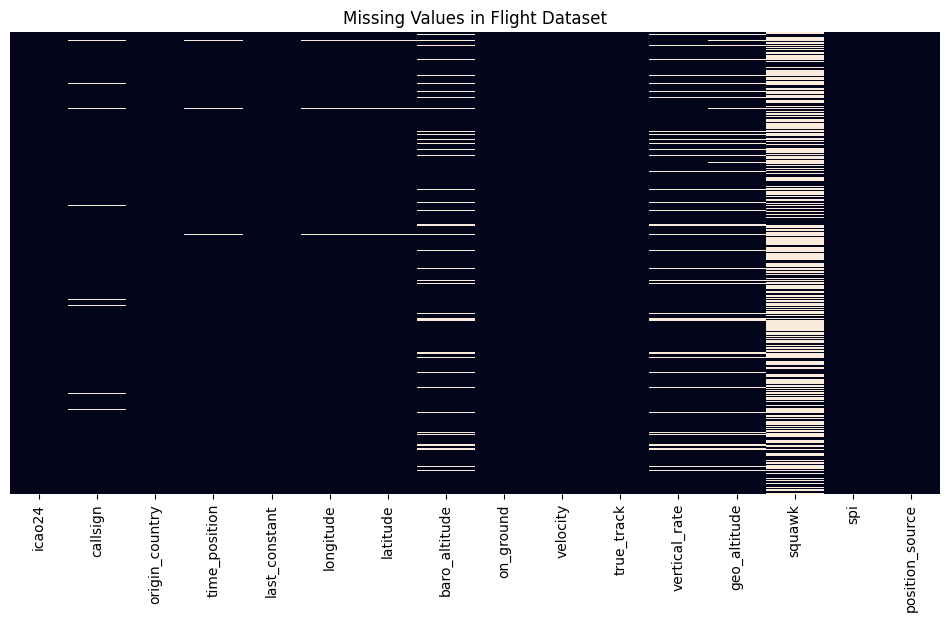

In [37]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)


plt.title("Missing Values in Flight Dataset")
plt.show()

<!-- Data cleaning and validation -->

Creating a Working Copy

In [38]:
clean = df.copy()

# Standardize column names
clean.columns = (
    clean.columns
    .str.strip()
    .str.lower()
)

# Remove whitespace from text fields
for col in ["icao24", "callsign", "origin_country"]:
    clean[col] = clean[col].astype("string").str.strip()

# Convert empty strings to missing values
clean["callsign"] = clean["callsign"].replace("", pd.NA)

print(clean.shape)

(7561, 16)


Remove exact duplicate records

In [39]:
clean = clean.drop_duplicates()

print("Shape after duplicates:", clean.shape)

Shape after duplicates: (7561, 16)


Convert timestamps

In [40]:
clean["time_position"] = pd.to_datetime(
    clean["time_position"],
    unit="s",
    utc=True,
    errors="coerce"
)

# Check the second timestamp column
clean["last_constant"] = pd.to_datetime(
    clean["last_constant"],
    unit="s",
    utc=True,
    errors="coerce"
)

display(clean[[
    "icao24",
    "time_position",
    "last_constant"
]].head())

,icao24,time_position,last_constant
0,80162d,2026-01-07 00:17:28+00:00,2026-01-07 00:17:28+00:00
1,ae1fa0,2026-01-07 00:17:27+00:00,2026-01-07 00:17:27+00:00
2,ac96b8,2026-01-07 00:17:28+00:00,2026-01-07 00:17:28+00:00
3,c81bd3,2026-01-07 00:15:17+00:00,2026-01-07 00:15:17+00:00
4,aa56db,2026-01-07 00:17:28+00:00,2026-01-07 00:17:28+00:00


Validate geographical coordinates

In [41]:
invalid_lat = clean["latitude"].between(-90, 90)

invalid_lon = clean["longitude"].between(-180, 180)

clean["invalid_coordinates"] = (
    invalid_lat | invalid_lon
)

print("Invalid coordinate records:",
      clean["invalid_coordinates"].sum())

Invalid coordinate records: 7516


Identify suspicious measurements

In [42]:
clean["invalid_speed"] = (
    (clean["velocity"] < 0) |
    (clean["velocity"] > 400)
)

clean["invalid_track"] = (
    ~clean["true_track"].between(0, 360)
)

clean["negative_altitude_flag"] = (
    clean["baro_altitude"] < 0
)

clean["missing_position_flag"] = (
    clean["latitude"].isna() |
    clean["longitude"].isna()
)

display(clean[[
    "icao24",
    "velocity",
    "baro_altitude",
    "vertical_rate",
    "invalid_speed",
    "invalid_track",
    "negative_altitude_flag"
]].head())

,icao24,velocity,baro_altitude,vertical_rate,invalid_speed,invalid_track,negative_altitude_flag
0,80162d,257.34,9608.82,5.20,False,False,False
1,ae1fa0,73.38,571.50,0.33,False,False,False
2,ac96b8,196.90,10363.20,0.00,False,False,False
3,c81bd3,56.90,624.84,0.65,False,False,False
4,aa56db,200.08,10972.80,0.00,False,False,False


Feature engineering

CONVERT UNITS

In [43]:
clean["speed_kmh"] = clean["velocity"] * 3.6

clean["altitude_ft"] = (
    clean["baro_altitude"] * 3.28084
)

clean["vertical_rate_fpm"] = (
    clean["vertical_rate"] * 196.8504
)

Classify aircraft flight status

In [44]:
def classify_flight(row):

    if pd.isna(row["on_ground"]):
        return "Unknown"

    if row["on_ground"]:
        return "Ground"

    if pd.isna(row["vertical_rate"]):
        return "Airborne - Unknown"

    if row["vertical_rate"] > 0.5:
        return "Climbing"

    elif row["vertical_rate"] < -0.5:
        return "Descending"

    else:
        return "Level Flight"


clean["flight_phase"] = clean.apply(
    classify_flight,
    axis=1
)

display(clean["flight_phase"].value_counts())

flight_phase
Level Flight          3659
Descending            1972
Climbing              1217
Ground                 697
Airborne - Unknown      16
Name: count, dtype: int64

Create data quality flags

In [45]:
clean["data_quality_issue"] = (
    clean["invalid_coordinates"] |
    clean["invalid_speed"] |
    clean["invalid_track"] |
    clean["missing_position_flag"]
)

print(clean["data_quality_issue"].value_counts())

data_quality_issue
True    7561
Name: count, dtype: int64


In [46]:
clean.to_csv(
    "opensky_data_cleaned.csv",
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


Exploratory data analysis(EDA)

Airborne vs ground aircraft

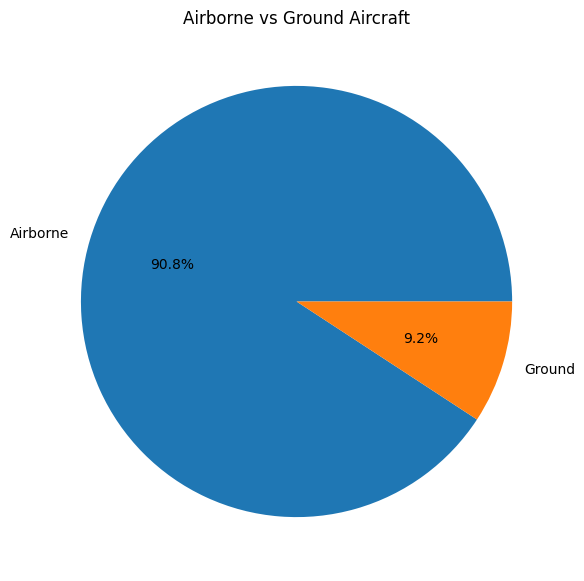

In [47]:
status = clean["on_ground"].value_counts()

status.index = ["Airborne", "Ground"]

status.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7)
)

plt.title("Airborne vs Ground Aircraft")
plt.ylabel("")
plt.show()

Top 10 Countries

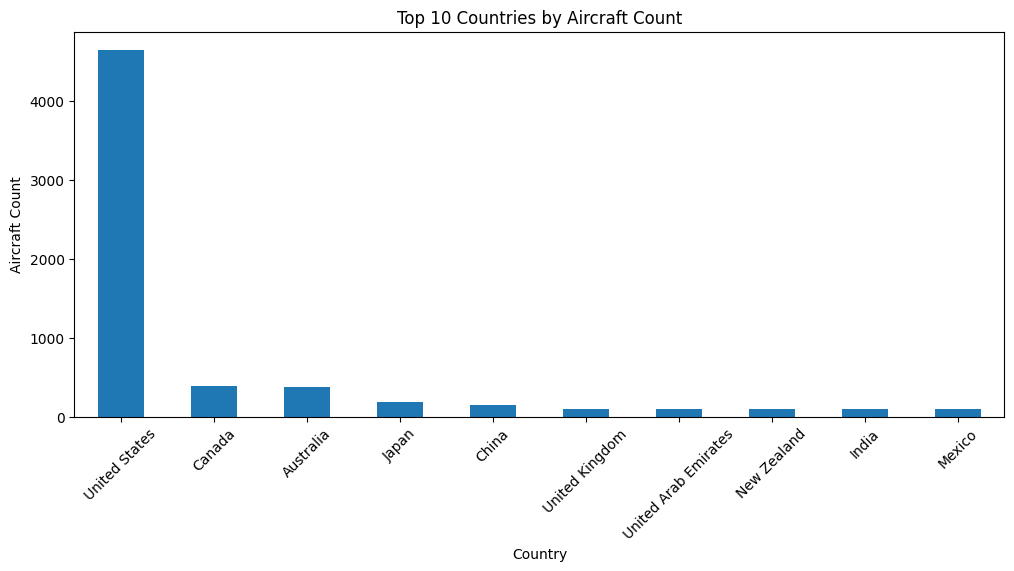

In [48]:
top_countries = (
    clean.groupby("origin_country")["icao24"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

top_countries.plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Top 10 Countries by Aircraft Count")
plt.xlabel("Country")
plt.ylabel("Aircraft Count")
plt.xticks(rotation=45)
plt.show()

Speed Distribution

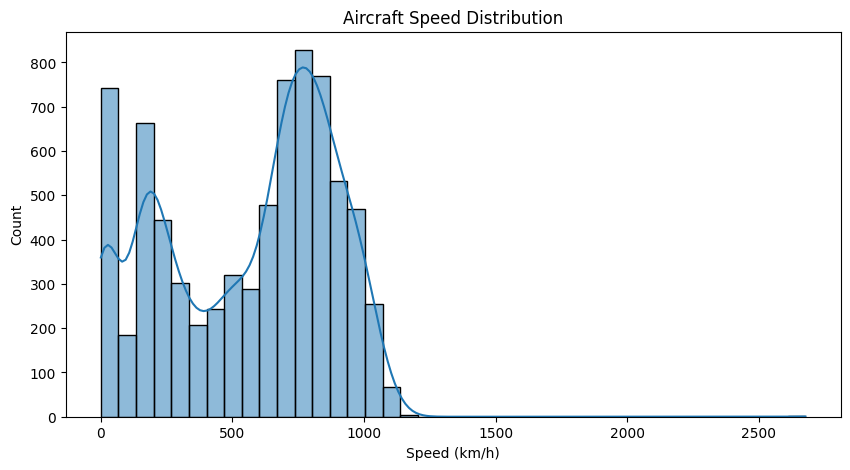

In [49]:
plt.figure(figsize=(10, 5))

sns.histplot(
    clean["speed_kmh"].dropna(),
    bins=40,
    kde=True
)

plt.title("Aircraft Speed Distribution")
plt.xlabel("Speed (km/h)")
plt.show()

Altitude distribution

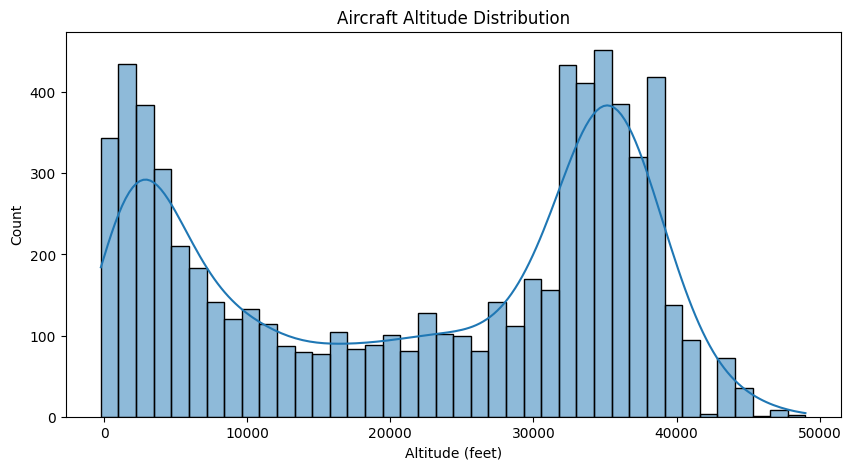

In [50]:
plt.figure(figsize=(10, 5))

sns.histplot(
    clean["altitude_ft"].dropna(),
    bins=40,
    kde=True
)

plt.title("Aircraft Altitude Distribution")
plt.xlabel("Altitude (feet)")
plt.show()

Vertical rate

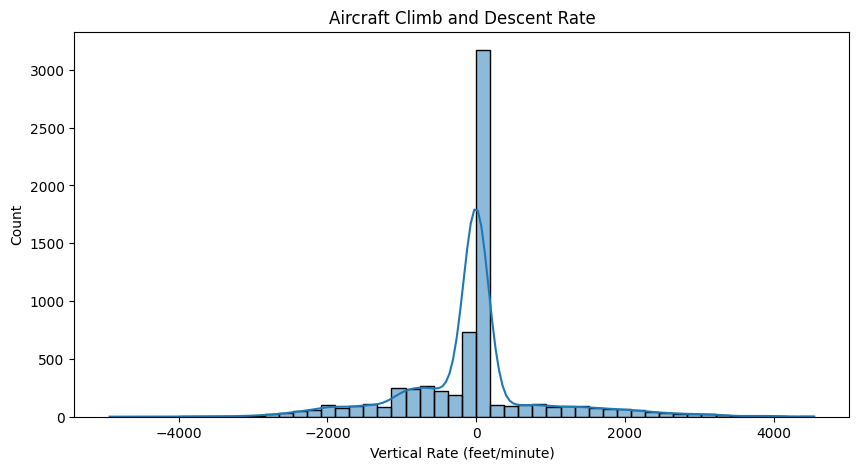

In [51]:
plt.figure(figsize=(10, 5))

sns.histplot(
    clean["vertical_rate_fpm"].dropna(),
    bins=50,
    kde=True
)

plt.title("Aircraft Climb and Descent Rate")
plt.xlabel("Vertical Rate (feet/minute)")
plt.show()

Geographical aircraft distribution

In [52]:
pip install plotly

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [53]:
pip install ipython nbformat

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [54]:
import plotly.express as px

map_df = clean.dropna(
    subset=["latitude", "longitude"]
)

fig = px.scatter_geo(
    map_df,
    lat="latitude",
    lon="longitude",
    color="flight_phase",
    hover_name="callsign",
    hover_data=["origin_country", "speed_kmh",
                "altitude_ft"],
    title="Global Aircraft Position Distribution"
)

fig.show()

Country Wise Spped Comparison

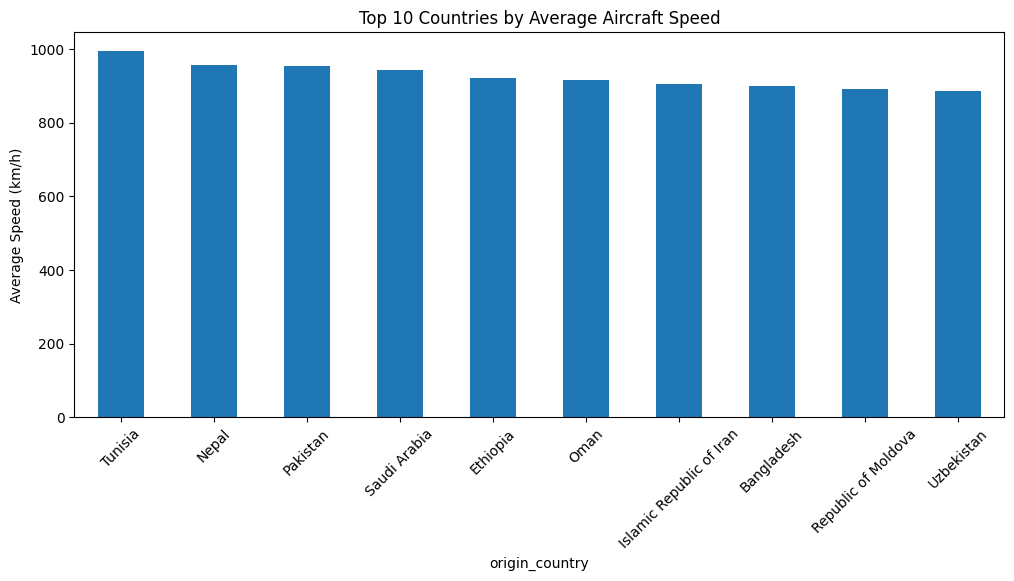

In [55]:
country_speed = (
    clean.groupby("origin_country")["speed_kmh"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

country_speed.plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Top 10 Countries by Average Aircraft Speed")
plt.ylabel("Average Speed (km/h)")
plt.xticks(rotation=45)
plt.show()

<!-- Data filtering and noise reduction -->

Range-based filtering

In [56]:
filtered = clean[
    clean["latitude"].between(-90, 90) &
    clean["longitude"].between(-180, 180) &
    clean["true_track"].between(0, 360) &
    (clean["velocity"].between(0, 400))
].copy()

print("Original records:", len(clean))
print("After filtering:", len(filtered))
print("Removed records:", len(clean) - len(filtered))

Original records: 7561
After filtering: 7515
Removed records: 46


Moving average filtering

In [57]:
repeated = clean[
    clean["icao24"].isin(
        clean["icao24"].value_counts()
        .loc[lambda x: x > 1].index
    )
].copy()

print(repeated.groupby("icao24").size())

icao24
8.99E+04    2
8.99E+07    2
dtype: int64


In [58]:
for aircraft_id, group in repeated.groupby("icao24"):

    if len(group) < 3:
        continue

    plt.figure(figsize=(10, 4))

    plt.plot(
        group["time_position"],
        group["speed_kmh"],
        marker="o",
        label="Original"
    )

    plt.plot(
        group["time_position"],
        group["smoothed_speed"],
        marker="o",
        label="Smoothed"
    )

    plt.title(f"Speed Filtering: {aircraft_id}")
    plt.legend()
    plt.show()

Aircraft movement analysis

In [59]:
from math import radians, sin, cos, asin, sqrt

def haversine(lat1, lon1, lat2, lon2):

    lat1, lon1, lat2, lon2 = map(
        radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        sin(dlat / 2)**2 +
        cos(lat1) * cos(lat2) *
        sin(dlon / 2)**2
    )

    return 6371 * 2 * asin(sqrt(a))


repeated = repeated.dropna(
    subset=["latitude", "longitude"]
).copy()

repeated = repeated.sort_values(
    ["icao24", "time_position"]
)

repeated["previous_lat"] = (
    repeated.groupby("icao24")["latitude"].shift(1)
)

repeated["previous_lon"] = (
    repeated.groupby("icao24")["longitude"].shift(1)
)

repeated["distance_km"] = repeated.apply(
    lambda r: haversine(
        r["previous_lat"],
        r["previous_lon"],
        r["latitude"],
        r["longitude"]
    )
    if pd.notna(r["previous_lat"]) else np.nan,
    axis=1
)

display(repeated[[
    "icao24",
    "time_position",
    "distance_km"
]])

,icao24,time_position,distance_km
5631,8.99E+04,2026-01-07 00:17:23+00:00,NaN
5153,8.99E+04,2026-01-07 00:17:28+00:00,11661.780216
5154,8.99E+07,2026-01-07 00:17:27+00:00,NaN
5629,8.99E+07,2026-01-07 00:17:27+00:00,227.169922


In [60]:
from sqlalchemy import create_engine

# Step 1: Connect to PostgreSQL
# Replace placeholders with your actual details
username = "postgres"      # default user
password = "suyash" # the password you set during installation
host = "localhost"         # if running locally
port = 5432             # default PostgreSQL port
database = "flight_analysis"    # the database you created in pgAdmin

engine = create_engine(f"postgresql+psycopg2://{username}:{password}@{host}:{port}/{database}")

# Step 2: Load DataFrame into PostgreSQL
table_name = "aircraft_states"   # choose any table name
df.to_sql(table_name, engine, if_exists="replace", index=False)

print(f"Data successfully loaded into table '{table_name}' in database '{database}'.")


# import psycopg2
# conn = psycopg2.connect(
#     host="localhost",
#     database="customer_behaviour",
#     port=5432,
#     user="postgres",
#     password="suyash"
# )

Data successfully loaded into table 'aircraft_states' in database 'flight_analysis'.
